# 01 — Dataset QC

This notebook loads the final modelling dataset, checks it against the shared schema contract, and gets a proper look at it — counts, missingness, distributions, completeness, duplicates — before any feature engineering or modelling starts. The inclusion criteria worked out here are what notebooks 02–05 take as given.

The actual logic lives in `dataset_contract.py`; this notebook just calls it and looks at the results.


> Real data throughout: this loads the actual final dataset from the 871-paper production run (`data/datasets_v2/production_run/cpp_dataset_v2.csv`, 297 observations from 51 papers).


## Imports

In [1]:
import sys
from pathlib import Path

# Project root = two levels up from notebooks/modelling/ -- works regardless of
# whose machine this runs on, as long as the repo layout is unchanged.
PROJECT_ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "modelling" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd

from literature_pipeline.modelling import dataset_contract as dc
from literature_pipeline.modelling import modelling_lib as ml

# NOTE: this notebook is a thin experiment/analysis layer over
# literature_pipeline/modelling/dataset_contract.py and modelling_lib.py.
# No modelling/CV logic should be duplicated here -- if a new operation
# is needed, it belongs in the .py library, not inline in a cell.

## Configuration

Points at the real path to the final production dataset. `ProvenanceColumnMap` matches the actual column names Stage 3 / the dataset builder produced — checked against the real CSV header, not assumed.


In [2]:
FINAL_DATASET_PATH = PROJECT_ROOT / "data" / "datasets_v2" / "production_run" / "cpp_dataset_v2.csv"
AUDIT_PATH = PROJECT_ROOT / "data" / "datasets_v2" / "production_run" / "cpp_dataset_v2_audit.jsonl"

PROVENANCE_COLUMN_MAP = dc.ProvenanceColumnMap(
    material_identity_status_column="material_identity_status",
    processing_identity_status_column="processing_identity_status",
    target_provenance_verified_column={
        "UTS_MPa": "UTS_provenance_verified",
        "YS_MPa": "YS_provenance_verified",
        "elongation_pct": "elongation_provenance_verified",
    },
    stage3_observation_status_column="stage3_observation_status",
)

## Expected input

A tabular dataset, one row per observation, satisfying `dataset_contract.REQUIRED_IDENTITY_COLUMNS` and `dataset_contract.TARGET_COLUMNS`. The contract doesn't fix composition/processing columns, so those get inspected here rather than assumed.

## Expected output of this notebook

- A `ValidationReport` confirming (or rejecting) minimum structural validity.
- Descriptive tables and plots: paper/material/observation counts, target availability, missingness, target distributions, composition/processing completeness, duplicate and suspicious-value flags.
- A clear statement of the inclusion criteria the later notebooks can rely on.


## Load final modelling dataset

In [3]:
df = pd.read_csv(FINAL_DATASET_PATH)
df.shape

(297, 53)

## Validate schema

In [4]:
report = dc.validate_minimum_structure(df, provenance_map=PROVENANCE_COLUMN_MAP)
report

ValidationReport(ok=True, missing_required_columns=[], missing_target_columns=[], has_any_target_data=True, missing_provenance_columns=[], warnings=[])

## Paper / material / observation counts

In [5]:
# observation_id AND condition_id are assigned PER PAPER by Stage 3 (e.g. "M1-P1-O1",
# "M1-P1"), exactly like material_id -- none of the three are globally unique across the
# corpus. Every count below is scoped by (doi, ...) for this reason; raw .nunique() on
# any of these three columns alone UNDERCOUNTS.
n_papers = df[dc.GROUP_COLUMN].nunique()
n_materials_scoped = df.groupby([dc.GROUP_COLUMN, "material_id"], dropna=False).ngroups
n_conditions_scoped = df.groupby([dc.GROUP_COLUMN, "material_id", "condition_id"], dropna=False).ngroups
n_observations_scoped = df.groupby([dc.GROUP_COLUMN, "observation_id"], dropna=False).ngroups

print(f"papers (unique DOI):                     {n_papers}")
print(f"materials (scoped by doi+material_id):    {n_materials_scoped}")
print(f"conditions (scoped by doi+material_id+condition_id): {n_conditions_scoped}")
print(f"observations (scoped by doi+observation_id): {n_observations_scoped}")
print(f"rows per paper -- median: {df.groupby(dc.GROUP_COLUMN).size().median():.0f}, "
      f"max: {df.groupby(dc.GROUP_COLUMN).size().max()}")

# Every row in the flat dataset IS one observation by construction (the dataset builder
# emits one row per valid_observation) -- assert this rather than assume it.
assert n_observations_scoped == len(df), (
    f"expected one row per (doi, observation_id), got {n_observations_scoped} != {len(df)}"
)
print(f"\nconfirmed: {len(df)} rows == {n_observations_scoped} scoped observations (1:1, as expected)")

papers (unique DOI):                     51
materials (scoped by doi+material_id):    76
conditions (scoped by doi+material_id+condition_id): 114
observations (scoped by doi+observation_id): 297
rows per paper -- median: 4, max: 24

confirmed: 297 rows == 297 scoped observations (1:1, as expected)


## Target availability

In [6]:
target_summary = []
for target in dc.TARGET_COLUMNS:
    n_nonnull = df[target].notna().sum()
    n_unique_dois = df.loc[df[target].notna(), dc.GROUP_COLUMN].nunique()
    target_summary.append({
        "target": target,
        "n_observations": n_nonnull,
        "fraction_of_rows": round(n_nonnull / len(df), 3),
        "n_unique_dois": n_unique_dois,
    })
target_summary_df = pd.DataFrame(target_summary)
target_summary_df

,target,n_observations,fraction_of_rows,n_unique_dois
0,UTS_MPa,197,0.663,42
1,YS_MPa,193,0.650,39
2,elongation_pct,139,0.468,29


## Missingness

In [7]:
identity_cols = dc.REQUIRED_IDENTITY_COLUMNS
target_cols = dc.TARGET_COLUMNS
composition_cols = dc.CORE_COMPOSITION_ELEMENTS
processing_cols = ["processing_key", "test_conditions_status"]

null_fraction = df[identity_cols + target_cols + composition_cols + processing_cols].isna().mean().sort_values(ascending=False)
null_fraction.to_frame("null_fraction")

,null_fraction
V,0.942761
Mo,0.892256
Nb,0.888889
N,0.865320
Cu,0.831650
Ti,0.818182
Ni,0.784512
P,0.771044
S,0.771044
Cr,0.666667


## Target distributions

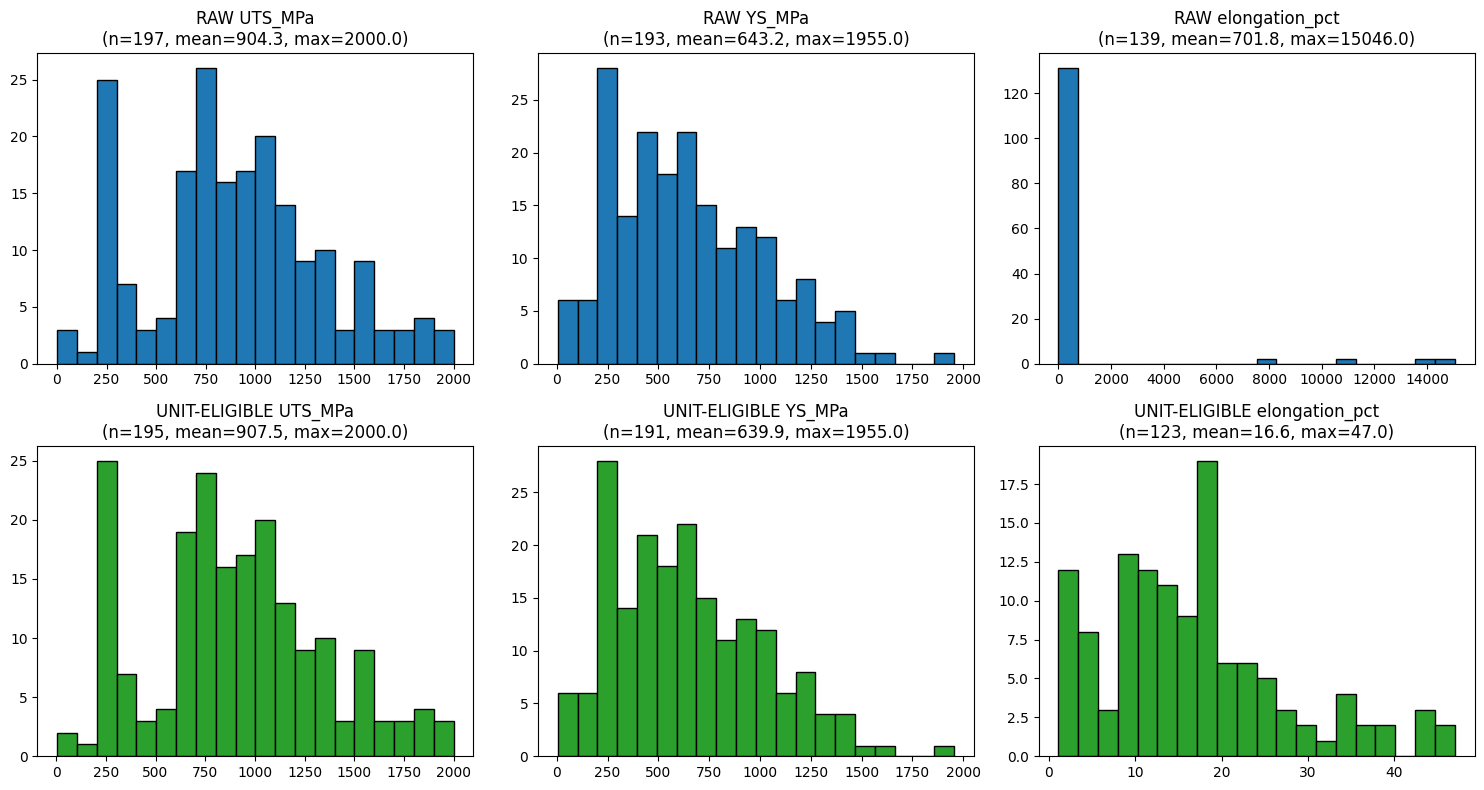

RAW (uncorrected) target stats:
           UTS_MPa       YS_MPa  elongation_pct
count   197.000000   193.000000      139.000000
mean    904.258274   643.168756      701.824820
std     439.191186   372.270116     2871.092621
min       1.200000     5.000000        1.100000
25%     651.000000   365.000000        9.650000
50%     860.000000   607.000000       16.400000
75%    1170.400000   916.000000       24.200000
max    2000.000000  1955.000000    15046.000000

Note: the top row includes rows with unit_verified == False (e.g. the 8 mislabelled elongation rows investigated below) -- it is NOT the dataset to model on. The bottom row is a predefined unit-compatible SUBSET, not a claim of 'cleaned truth'.


In [8]:
import matplotlib.pyplot as plt

unit_verified_cols = {
    "UTS_MPa": "UTS_unit_verified",
    "YS_MPa": "YS_unit_verified",
    "elongation_pct": "elongation_unit_verified",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col_i, target in enumerate(dc.TARGET_COLUMNS):
    raw_vals = df[target].dropna()
    axes[0, col_i].hist(raw_vals, bins=20, edgecolor="black")
    axes[0, col_i].set_title(f"RAW {target}\n(n={len(raw_vals)}, mean={raw_vals.mean():.1f}, max={raw_vals.max():.1f})")

    verified_col = unit_verified_cols[target]
    eligible = df[df[target].notna() & (df[verified_col] == True)]
    vals = eligible[target]
    axes[1, col_i].hist(vals, bins=20, edgecolor="black", color="tab:green")
    axes[1, col_i].set_title(f"UNIT-ELIGIBLE {target}\n(n={len(vals)}, mean={vals.mean():.1f}, max={vals.max():.1f})")
plt.tight_layout()
plt.show()

print("RAW (uncorrected) target stats:")
print(df[dc.TARGET_COLUMNS].describe())
print("\nNote: the top row includes rows with unit_verified == False (e.g. the 8 "
      "mislabelled elongation rows investigated below) -- it is NOT the dataset to model on. "
      "The bottom row is a predefined unit-compatible SUBSET, not a claim of 'cleaned truth'.")

## Composition / processing completeness

In [9]:
comp_coverage = pd.DataFrame({
    "element": dc.CORE_COMPOSITION_ELEMENTS,
    "n_nonnull": [df[e].notna().sum() for e in dc.CORE_COMPOSITION_ELEMENTS],
    "fraction": [round(df[e].notna().mean(), 3) for e in dc.CORE_COMPOSITION_ELEMENTS],
}).sort_values("fraction", ascending=False)
comp_coverage

,element,n_nonnull,fraction
2,Si,165,0.556
1,Mn,156,0.525
0,C,127,0.428
3,Al,113,0.380
4,Cr,99,0.333
11,P,68,0.229
12,S,68,0.229
5,Ni,64,0.215
8,Ti,54,0.182
10,Cu,50,0.168


In [10]:
n_with_any_composition = (df[dc.CORE_COMPOSITION_ELEMENTS].notna().any(axis=1)).sum()
print(f"rows with >=1 composition element: {n_with_any_composition} / {len(df)} "
      f"({n_with_any_composition/len(df):.1%})")

print("\nprocessing_key non-null:", df["processing_key"].notna().sum(), "/", len(df))
print("\ntest_conditions_status value counts:")
df["test_conditions_status"].value_counts(dropna=False)

rows with >=1 composition element: 170 / 297 (57.2%)

processing_key non-null: 255 / 297

test_conditions_status value counts:


test_conditions_status
unresolved            204
confirmed_explicit     64
default_implicit       29
Name: count, dtype: int64

## Duplicates / suspicious values

In [11]:
# Use the full REQUIRED_IDENTITY_COLUMNS key explicitly, per the dataset contract,
# rather than a subset -- observation_id and condition_id are both paper-scoped (like
# material_id), so any duplicate check must include doi.
identity_key = dc.REQUIRED_IDENTITY_COLUMNS  # ["doi", "material_id", "condition_id", "observation_id"]
duplicate_identity = df[df.duplicated(identity_key, keep=False)]
print(f"duplicate rows on full identity key {identity_key}: {len(duplicate_identity)}")

# A (doi, material_id, condition_id) triple CAN legitimately repeat across rows --
# each row is one observation_id (i.e. typically one resolved property value), and a
# single processing condition can have multiple observations (different properties,
# replicates, or test contexts). This is NOT itself evidence of "multiple properties
# packed into one row" -- the CSV is one-row-per-observation by construction. We only
# checked the WEAKER triple here for descriptive purposes; the identity_key check above
# is the actual uniqueness guarantee.
dup_condition_triple = df[df.duplicated(["doi", "material_id", "condition_id"], keep=False)]
print(f"rows sharing the same (doi, material_id, condition_id) [descriptive only, "
      f"not a uniqueness violation]: {len(dup_condition_triple)}")

duplicate rows on full identity key ['doi', 'material_id', 'condition_id', 'observation_id']: 0
rows sharing the same (doi, material_id, condition_id) [descriptive only, not a uniqueness violation]: 225


In [12]:
# Flag only -- consistent with the dataset builder's own QC report
# (cpp_dataset_v2_qc_report.json), which already found these same warnings.
suspicious = []

uts_lt_ys = df[(df["UTS_MPa"].notna()) & (df["YS_MPa"].notna()) & (df["UTS_MPa"] < df["YS_MPa"])]
suspicious.append(("UTS_MPa < YS_MPa", uts_lt_ys["observation_id"].tolist()))

elong_gt_100 = df[(df["elongation_pct"].notna()) & (df["elongation_pct"] > 100)]
suspicious.append(("elongation_pct > 100", elong_gt_100["observation_id"].tolist()))

comp_sum = df[dc.CORE_COMPOSITION_ELEMENTS].sum(axis=1, skipna=True)
comp_over_100 = df[comp_sum > 100]
suspicious.append(("sum of composition elements > 100 wt.%", comp_over_100["observation_id"].tolist()))

for check, ids in suspicious:
    print(f"[{len(ids):3d}] {check}: {ids}")

[  2] UTS_MPa < YS_MPa: ['M1-P1-O7', 'M1-P1-O12']
[  8] elongation_pct > 100: ['M1-P1-O1', 'M1-P1-O2', 'M1-P1-O3', 'M1-P1-O4', 'M2-P1-O1', 'M2-P1-O2', 'M2-P1-O3', 'M2-P1-O4']
[  2] sum of composition elements > 100 wt.%: ['M3-P1-O1', 'M3-P1-O2']


### Investigating the 8 `elongation_pct > 100` rows

Rather than guessing from the magnitude alone, I checked `elongation_unit_verified` (did the pipeline's own flag already catch these?) against the audit trail's `source_column` and `table_caption`, to see what these values are actually measuring.


In [13]:
print(elong_gt_100[["observation_id", "doi", "material_id", "elongation_pct",
                     "elongation_reported_unit", "elongation_unit_verified"]].to_string(index=False))

# unit_verified == False means the pipeline FLAGGED the unit mismatch -- it does NOT mean
# the value was kept out of the flat dataset. It is still sitting in elongation_pct and
# would silently pollute any model trained without explicitly filtering on this column.
assert not elong_gt_100["elongation_unit_verified"].any(), "expected all flagged as unverified"
print("\nConfirmed: elongation_unit_verified == False for all 8 rows -- Stage 3 flagged the "
      "unit mismatch, but the incompatible values remain in the flat CSV and require explicit "
      "exclusion (in 02) before modelling; they were not prevented from entering it.")

# What are these values actually measuring? Check the audit trail's source evidence
# instead of guessing from unit + magnitude alone.
import json as _json
target_doi = elong_gt_100["doi"].iloc[0]
with open(AUDIT_PATH) as f:
    for line in f:
        rec = _json.loads(line)
        if rec.get("observation_id") == elong_gt_100["observation_id"].iloc[0] and rec.get("doi") == target_doi:
            prop = rec["properties"]["elongation_unspecified"]
            print(f"\nsource_column: {prop['source_column']!r}")
            print(f"table_caption: {prop['source_context']['table_caption']!r}")
            break

observation_id                        doi material_id  elongation_pct elongation_reported_unit  elongation_unit_verified
      M1-P1-O1 10.1016/j.msea.2026.150164          M1         10910.0                      MPa                     False
      M1-P1-O2 10.1016/j.msea.2026.150164          M1          7590.0                      MPa                     False
      M1-P1-O3 10.1016/j.msea.2026.150164          M1         14141.0                      MPa                     False
      M1-P1-O4 10.1016/j.msea.2026.150164          M1         15046.0                      MPa                     False
      M2-P1-O1 10.1016/j.msea.2026.150164          M2         10910.0                      MPa                     False
      M2-P1-O2 10.1016/j.msea.2026.150164          M2          7590.0                      MPa                     False
      M2-P1-O3 10.1016/j.msea.2026.150164          M2         14141.0                      MPa                     False
      M2-P1-O4 10.1016/j.msea.20

The source column turns out to be `"Area Uniform EL (MPa-%)"`, and the table's own caption spells out exactly what that is: *"Area Uniform EL (MPa-%) is the area under the engineering stress–strain curve up to uniform elongation"* — a combined strength–ductility metric (units MPa·%), not percentage elongation at all. The bare `"EL"` inside that compound header must have matched Stage 2's elongation alias detector, producing a real false-positive alias match. Worth recording for the dissertation's error-analysis section, but nothing to fix here.

One more thing I noticed but haven't resolved: the same four values (10910, 7590, 14141, 15046) show up identically under both `M1` and `M2` for this paper. Could just mean the two materials share one source table — plausible, but I haven't checked it against the actual table structure, so I'm leaving it as an open question rather than concluding anything.


### Investigating the extreme low UTS/YS values and the composition-sum>100 rows

Same approach as above — audit-trail evidence, not just magnitude or unit.


In [14]:
low_uts = df.nsmallest(3, "UTS_MPa")[["doi", "observation_id", "UTS_MPa", "UTS_reported_unit", "UTS_unit_verified"]]
low_ys = df.nsmallest(3, "YS_MPa")[["doi", "observation_id", "YS_MPa", "YS_reported_unit", "YS_unit_verified"]]
print("lowest UTS_MPa:"); print(low_uts.to_string(index=False))
print("\nlowest YS_MPa:"); print(low_ys.to_string(index=False))

lowest UTS_MPa:
                           doi observation_id  UTS_MPa UTS_reported_unit  UTS_unit_verified
    10.1016/j.jmrt.2021.07.045       M1-P1-O1      1.2               GPa              False
10.1016/j.ijmecsci.2025.110565       M1-P1-O7      4.8               MPa               True
10.1016/j.ijmecsci.2025.110565      M1-P1-O12      5.1               MPa               True

lowest YS_MPa:
                           doi observation_id  YS_MPa YS_reported_unit  YS_unit_verified
10.1016/j.ijmecsci.2025.110565       M1-P1-O7     5.0              MPa              True
10.1016/j.ijmecsci.2025.110565      M1-P1-O12     8.7              MPa              True
    10.1016/j.jmrt.2023.10.233       M1-P1-O3    24.0              MPa              True


The first is a real error, and I've corrected it here: `UTS_MPa == 1.2` is actually a 1.2 GPa value that never got converted to MPa. The audit trail for `10.1016/j.jmrt.2021.07.045 / M1-P1-O1` reads `value: 1.2, reported_unit: "GPa", verification_status: verified_from_local_text` — the source text states "1.2 GPa" directly, so this is confirmed, not inferred, and the ×1000 conversion is deterministic rather than an estimate. I've applied it through the shared `modelling_lib.apply_known_data_corrections()` below, so 02 and 03 pick up the identical correction rather than each notebook editing the value inline.

The second is the DP780 rows, which are a confirmed inconsistency with only a probable cause. The audit trail for `10.1016/j.ijmecsci.2025.110565 / M1-P1-O7` and `/M1-P1-O12` shows `source_column: "Ultimate Tensile Strength Rm [MPa]"` / `"Yield Strength Rp0.2 [MPa]"`, `verification_status: verified_from_table_header`, but UTS=4.8 < YS=5.0 (and UTS=5.1 < YS=8.7) for the same observation. That's a physical impossibility on its own terms — UTS is by definition ≥ YS in a standard tensile test — regardless of what DP780's nominal strength should be. So the inconsistency itself is confirmed; only the likely cause (a table row-alignment error) is unverified against the raw table. Since a confirmedly inconsistent row doesn't belong in anything called "sensitivity" (which should only relax the unit-verification requirement, not admit rows that are confirmed bad), both rows are excluded from both `primary` and `sensitivity`, and only appear in a separate `diagnostic_suspect_inclusive` cohort — kept purely to show what the results would look like without this audit, never reported as the actual robustness comparison.


In [15]:
comp_over_100 = df[df[dc.CORE_COMPOSITION_ELEMENTS].sum(axis=1, skipna=True) > 100]
print(comp_over_100[["doi", "observation_id", "material_id"] + dc.CORE_COMPOSITION_ELEMENTS].dropna(axis=1, how="all").to_string(index=False))

import json as _json
with open(AUDIT_PATH) as f:
    for line in f:
        rec = _json.loads(line)
        if rec.get("observation_id") == "M3-P1-O1" and rec.get("doi") == "10.1007/s40194-026-02341-1":
            for e in rec["full_composition"]["elements"]:
                if e["element"] == "Cu":
                    print("\nCu raw evidence:", _json.dumps(e, indent=2))
            break

                       doi observation_id material_id    Cu
10.1007/s40194-026-02341-1       M3-P1-O1          M3 999.0
10.1007/s40194-026-02341-1       M3-P1-O2          M3 999.0

Cu raw evidence: {
  "element": "Cu",
  "reported_value": "99,9",
  "reported_unit": "wt.%",
  "value": 999.0,
  "qualifier": "exact",
  "range_low": null,
  "range_high": null,
  "provenance": {
    "location": {
      "type": "table",
      "table_index": 1,
      "row_index": 2,
      "column": "Cu"
    },
    "verified": true
  }
}


The last one is `Cu=999`, which turns out to be a decimal-comma misparse — `reported_value: "99,9"` is European decimal-comma notation (99.9, not 999) that got misread as a thousands-grouped integer. But 99.9 wt.% Cu is physically meaningless for a steel either way (steel is predominantly Fe), so fixing the decimal parse doesn't actually make the row valid. I'm excluding the `M3-P1-O1`/`M3-P1-O2` (`10.1007/s40194-026-02341-1`) Cu value from any composition-sum check; what that table cell actually represents is still unresolved, and chasing it further is out of scope here.


### Closing the audit: the remaining 11 non-primary rows

That leaves 11 rows (1 elongation-GPa, 7 elongation-unit-missing, 1 UTS-unit-missing, 2 YS-unit-missing). I traced each one individually to its `source_column`, `reported_unit`, and `unit_verification_status` in the audit trail before calling this notebook done.


In [16]:
import json as _json
with open(AUDIT_PATH) as f:
    _audit_recs = {(r["doi"], r["observation_id"]): r for r in (_json.loads(l) for l in f)}

_to_check = [
    ("10.1016/j.matdes.2025.114234", "M1-P1-O7", "elongation"),
    ("10.1016/j.corcom.2026.04.005", "M1-P1-O5", "elongation"),
    ("10.1016/j.heliyon.2024.e32101", "M1-P1-O2", "elongation"),
    ("10.1016/j.jalmes.2025.100214", "M2-P1-O4", "elongation"),
    ("10.1016/j.matdes.2025.114234", "M1-P1-O4", "elongation"),
    ("10.1016/j.matdes.2025.114234", "M1-P1-O5", "elongation"),
    ("10.1007/s11661-025-08095-7", "M1-P1-O1", "elongation"),
    ("10.1007/s11661-025-08095-7", "M2-P1-O1", "elongation"),
    ("10.1016/j.corcom.2026.04.005", "M1-P1-O4", "UTS"),
    ("10.1016/j.jmrt.2022.11.070", "M2-P1-O1", "YS"),
    ("10.1016/j.jmrt.2023.10.233", "M5-P1-O1", "YS"),
]
for doi, oid, prefix in _to_check:
    rec = _audit_recs.get((doi, oid))
    props = rec.get("properties", {}) if rec else {}
    match_key = next((k for k in props if k == prefix or k.startswith(prefix)), None)
    p = props.get(match_key, {})
    print(f"{doi} {oid} [{match_key}] value={p.get('value')} unit={p.get('reported_unit')} "
          f"verif={p.get('unit_verification_status')} col={p.get('source_column')}")

10.1016/j.matdes.2025.114234 M1-P1-O7 [elongation_total] value=30.4 unit=GPa verif=verified_from_local_text col=None
10.1016/j.corcom.2026.04.005 M1-P1-O5 [elongation_total] value=14.1 unit=None verif=reported_by_model_unverified col=None
10.1016/j.heliyon.2024.e32101 M1-P1-O2 [elongation_unspecified] value=1.3 unit=None verif=not_available col=Average thickness
10.1016/j.jalmes.2025.100214 M2-P1-O4 [elongation_total] value=27.6 unit=None verif=reported_by_model_unverified col=None
10.1016/j.matdes.2025.114234 M1-P1-O4 [elongation_uniform] value=24.8 unit=None verif=reported_by_model_unverified col=None
10.1016/j.matdes.2025.114234 M1-P1-O5 [elongation_uniform] value=21.0 unit=None verif=reported_by_model_unverified col=None
10.1007/s11661-025-08095-7 M1-P1-O1 [elongation_unspecified] value=8.5 unit=None verif=not_available col=AGS
10.1007/s11661-025-08095-7 M2-P1-O1 [elongation_unspecified] value=8.5 unit=None verif=not_available col=AGS
10.1016/j.corcom.2026.04.005 M1-P1-O4 [UTS] val

Classifying all 11 against the four-way rule — canonical-unit-recoverable, property-correct-but-unit-unclear, wrong-property, or cannot-decide:

| doi | obs_id | target | evidence | class |
|---|---|---|---|---|
| matdes.2025.114234 | M1-P1-O7 | elongation | `elongation_total`, reported in **GPa** — unit fundamentally incompatible with elongation | **wrong property/unit** |
| heliyon.2024.e32101 | M1-P1-O2 | elongation | `source_column="Average thickness"` (mm) | **wrong property** |
| 11661-025-08095-7 | M1-P1-O1, M2-P1-O1 | elongation | `source_column="AGS"` from a *composition* table | **wrong property** |
| corcom.2026.04.005 | M1-P1-O5 | elongation | `elongation_total`, no unit, no source_column, `reported_by_model_unverified` | **cannot decide** |
| jalmes.2025.100214 | M2-P1-O4 | elongation | same pattern, no grounding at all | **cannot decide** |
| matdes.2025.114234 | M1-P1-O4, M1-P1-O5 | elongation | `elongation_uniform`, no unit, no source_column, unverified | **cannot decide** |
| corcom.2026.04.005 | M1-P1-O4 | UTS | no unit, no source_column, unverified | **cannot decide** |
| jmrt.2022.11.070 | M2-P1-O1 | YS | `not_available`, no source_column | **cannot decide** |
| jmrt.2023.10.233 | M5-P1-O1 | YS | no unit, no source_column, unverified | **cannot decide** |

None of the 11 fall into "canonical unit recoverable" — unlike the 1.2 GPa case, none of them have an explicit unit statement in the source to convert from — or "property correct, unit merely unclear": the wrong-property ones are wrong regardless of unit, and the cannot-decide ones have no `source_column` at all, so it's the property itself that's unverifiable, not just its unit. All 11 are excluded from both `primary` and `sensitivity` — 4 as confirmed-wrong (joining the original 8 in `CONFIRMED_WRONG_ELONGATION_KEYS`, for 12 total) and 7 as cannot-decide (`CANNOT_DECIDE_KEYS`), both defined once in `modelling_lib.py` so 02 and 03 never have to re-derive this list.


### Target-specific eligibility table

Combines unit-verification status with composition presence, per target — these are the numbers 02 actually needs, not one dataset-wide completeness figure.


In [17]:
TARGET_UNIT_COLUMNS = {"UTS_MPa": "UTS_reported_unit", "YS_MPa": "YS_reported_unit", "elongation_pct": "elongation_reported_unit"}
# Shared, single-source correction/cohort rules -- see literature_pipeline/modelling/
# modelling_lib.py's "KNOWN DATA CORRECTIONS / EXCLUSIONS" section for the full audit
# trail behind every key below. 02/03 import these same two functions; nothing here is
# re-derived independently.
df = ml.apply_known_data_corrections(df)

rows = []
for target in dc.TARGET_COLUMNS:
    masks = ml.target_cohort_masks(df, target)
    value_col = ml.TARGET_VALUE_COLUMNS[target]
    comp_present = masks["primary"] & df[dc.CORE_COMPOSITION_ELEMENTS].notna().any(axis=1)
    rows.append({
        "target": target,
        "raw_n": int(df[value_col].notna().sum()),
        "primary_n": int(masks["primary"].sum()),
        "sensitivity_n": int(masks["sensitivity"].sum()),
        "diagnostic_suspect_inclusive_n": int(masks["diagnostic_suspect_inclusive"].sum()),
        "primary_DOI": df.loc[masks["primary"], "doi"].nunique(),
        "composition_present_n": int(comp_present.sum()),
        "composition_present_DOI": df.loc[comp_present, "doi"].nunique(),
    })
eligibility_table = pd.DataFrame(rows)
eligibility_table

,target,raw_n,primary_n,sensitivity_n,diagnostic_suspect_inclusive_n,primary_DOI,composition_present_n,composition_present_DOI
0,UTS_MPa,158,155,155,157,36,94,19
1,YS_MPa,157,153,153,155,32,95,20
2,elongation_pct,108,92,92,92,22,52,12


In [18]:
for target in dc.TARGET_COLUMNS:
    unit_col = TARGET_UNIT_COLUMNS[target]
    verified_col = ml.TARGET_UNIT_VERIFIED_COLUMNS[target]
    value_col = ml.TARGET_VALUE_COLUMNS[target]
    print(f"--- {target} ---")
    print(df.loc[df[value_col].notna()].groupby([unit_col, verified_col], dropna=False).size().rename("n").reset_index().to_string(index=False))
    print()

--- UTS_MPa ---
UTS_reported_unit  UTS_unit_verified   n
              GPa              False   1
              MPa               True 156
              NaN              False   1

--- YS_MPa ---
YS_reported_unit  YS_unit_verified   n
             MPa              True 155
             NaN             False   2

--- elongation_pct ---
elongation_reported_unit  elongation_unit_verified  n
                       %                      True 92
                     GPa                     False  1
                     MPa                     False  8
                     NaN                     False  7



### Descriptive statistics — unit-eligible and physically-plausible subset only

This is the `primary` cohort's target distribution: unit-verified, and not flagged as physically implausible above.


In [19]:
primary_stats = {}
for target in dc.TARGET_COLUMNS:
    masks = ml.target_cohort_masks(df, target)
    value_col = ml.TARGET_VALUE_COLUMNS[target]
    vals = df.loc[masks["primary"], value_col]
    primary_stats[target] = {
        "n": len(vals), "unique_DOI": df.loc[masks["primary"], "doi"].nunique(),
        "mean": vals.mean(), "std": vals.std(), "min": vals.min(),
        "25%": vals.quantile(0.25), "50%": vals.median(), "75%": vals.quantile(0.75), "max": vals.max(),
    }
pd.DataFrame(primary_stats).T

,n,unique_DOI,mean,std,min,25%,50%,75%,max
UTS_MPa,155.0,36.0,1049.613290,367.011058,279.0,791.950,1006.0,1265.4,2000.0
YS_MPa,153.0,32.0,728.284967,352.753618,24.0,466.000,686.0,941.0,1955.0
elongation_pct,92.0,22.0,18.867500,11.003341,1.1,11.575,18.0,24.1,47.0


## Steel-scope audit and composition sanity audit

I went through the title and reported grade label of all 51 DOIs in the dataset (`docs/scope_audit_v1.csv`, version-controlled) and found 6 non-steel papers and 1 mixed-material paper — 41 observations that aren't steel at all (aluminium alloys, a nickel superalloy, a NiTi shape-memory alloy, a Cu-based composite, and one Cu-foil weld insert). These are now excluded via `modelling_lib.exclude_non_steel_scope()` — a full-row exclusion, not a composition null — applied automatically inside `apply_known_data_corrections()`. `df` below is reloaded after this exclusion.


In [20]:
scope_audit = pd.read_csv(PROJECT_ROOT / "docs" / "scope_audit_v1.csv")
print(scope_audit["scope_status"].value_counts())
print(f"\nexcluded observations: {scope_audit.loc[scope_audit['scope_status'].isin(['non_steel','mixed_material']), 'n_final_observations'].sum()}")
print(f"\ndf shape BEFORE this cell (already scope-corrected via apply_known_data_corrections above): {df.shape}")

scope_status
steel             44
non_steel          6
mixed_material     1
Name: count, dtype: int64

excluded observations: 41

df shape BEFORE this cell (already scope-corrected via apply_known_data_corrections above): (256, 55)


### Composition sanity audit (steel-scoped observations only) — flags for review, not automatic deletion


In [21]:
comp_sum = df[dc.CORE_COMPOSITION_ELEMENTS].sum(axis=1, skipna=True)
has_any_comp = df[dc.CORE_COMPOSITION_ELEMENTS].notna().any(axis=1)

print("=== composition sum by scoped material (rows with >=1 element) ===")
print(comp_sum[has_any_comp].describe())

print("\n=== min/max per selected element (steel-scoped) ===")
print(df[dc.CORE_COMPOSITION_ELEMENTS].agg(['min', 'max']).T)

print("\n=== top 5 highest values per element (DOI/material) ===")
for e in dc.CORE_COMPOSITION_ELEMENTS:
    top5 = df.nlargest(5, e)[["doi", "material_id", e]].dropna(subset=[e])
    if len(top5):
        print(f"-- {e} --")
        print(top5.to_string(index=False))

print("\n=== rows with composition sum > 100% ===")
over100 = df[comp_sum > 100][["doi", "material_id", "observation_id"]].drop_duplicates()
print(over100.to_string(index=False) if len(over100) else "(none)")

print("\n=== duplicated composition profiles across DIFFERENT material_ids ===")
comp_profile = df[has_any_comp].groupby(["doi", "material_id"])[dc.CORE_COMPOSITION_ELEMENTS].first()
dup_mask = comp_profile.duplicated(keep=False)
dup_profiles = comp_profile[dup_mask].sort_values(list(comp_profile.columns))
print(dup_profiles.to_string() if len(dup_profiles) else "(none found)")

=== composition sum by scoped material (rows with >=1 element) ===
count    136.000000
mean       7.999050
std        6.036973
min        1.887300
25%        3.593000
50%        5.440000
75%       12.050000
max       30.476000
dtype: float64

=== min/max per selected element (steel-scoped) ===
       min     max
C   0.0130   0.760
Mn  0.4400   8.200
Si  0.1940   2.000
Al  0.0020   3.470
Cr  0.0180  18.260
Ni  0.0600  10.150
Mo  0.0400   2.070
Nb  0.0010   0.050
Ti  0.0190   0.050
V   0.0300   0.250
Cu  0.0200   1.500
P   0.0010   0.031
S   0.0007   0.011
N   0.0030   0.040

=== top 5 highest values per element (DOI/material) ===
-- C --
                       doi material_id    C
10.1016/j.jmrt.2024.01.054          M1 0.76
10.1016/j.jmrt.2024.01.054          M1 0.76
10.1016/j.jmrt.2024.01.054          M1 0.76
10.1016/j.jmrt.2024.01.054          M1 0.76
10.1016/j.jmrt.2024.01.054          M1 0.76
-- Mn --
                       doi material_id  Mn
10.1016/j.mtla.2022.101422          M2 

The Fe-balance check isn't really assessable here — `Fe` isn't a modelled column (steel composition is conventionally reported as alloying elements with Fe as the implicit balance, and this dataset doesn't carry an explicit Fe column to check against), so the composition-sum > 100% check above is the closest available proxy.

All the flags above are for review, not automatic deletion — nothing gets removed here based on this audit alone. Only the two source-confirmed corrections already applied (`exclude_non_steel_scope`, and the GPa fix inside `apply_known_data_corrections`) have actually changed a row.


## Inclusion criteria — decided from real data and source evidence above

No duplicates showed up on the full identity key `(doi, material_id, condition_id, observation_id)`, so there's no resolution policy needed there.

Three cohorts come out of this, defined once in `modelling_lib.py` (`apply_known_data_corrections` + `target_cohort_masks`) and reused identically by 02 and 03 rather than re-derived per notebook:

- `primary` — unit-verified (or manually, auditably corrected) and not caught by any known exclusion. This is the strict, main-result cohort.
- `sensitivity` — relaxes the unit-verification requirement, but still excludes every confirmed-wrong, cannot-decide, and confirmed-inconsistent row, since a cohort still containing proven-bad values wouldn't actually test anything. For `elongation_pct`, `primary` and `sensitivity` end up identical (123 rows), because every non-unit-verified elongation row turned out on audit to be either confirmed-wrong or cannot-decide — there just wasn't a genuinely "disputed but plausible" middle ground for this target.
- `diagnostic_suspect_inclusive` — `sensitivity` plus the confirmed-inconsistent DP780 rows put back in. This exists only to show what the results would look like without this audit; it should never be presented as the robustness result.

On composition: `Cu=999` (`10.1007/s40194-026-02341-1`) is confirmed to be a decimal-comma misparse (`"99,9"`), and the corrected value (99.9 wt.% Cu) is itself confirmed implausible for a steel, so it's excluded from composition-sum reasoning. Only 170 of 297 rows (57%) have any composition element at all — `composition_present_n`/`_DOI` above are computed specifically on the `primary` cohort — and 02 still has to decide how it wants to handle composition-incomplete rows per target.

The grouping unit for cross-validation in 03 and 05 is `doi`; `material_id`, `condition_id`, and `observation_id` are all paper-scoped, not globally unique.

Pulling together what the audit actually found, ranked by how confident I am in each, all traced back to `source_column`/`table_caption`/`reported_value`/`unit_verification_status` in the audit trail:

1. Confirmed — 12 elongation rows are actually a different property or unit entirely: 8 "Area Uniform EL (MPa-%)" alias rows, 1 thickness column, 2 composition-table "AGS" values, and 1 GPa-labelled `elongation_total`. Excluded from `primary` and `sensitivity`.
2. Confirmed, and corrected — one genuine 1.2 GPa `UTS_MPa` value, converted to 1200 MPa via `modelling_lib.apply_known_data_corrections`. Included in `primary`.
3. Inconsistency confirmed, root cause only probable — 2 DP780 rows, affecting both UTS and YS, have `UTS < YS`, which is a confirmed physical impossibility, most likely from a table-alignment error (not verified against the raw table). Excluded from both `primary` and `sensitivity`; only visible in `diagnostic_suspect_inclusive`.
4. Cannot decide — 7 rows (4 elongation, 1 UTS, 2 YS) have no captured unit and no `source_column` at all, so it's the property itself that's unverifiable, not just its unit. Excluded from `primary` and `sensitivity`.
5. Confirmed — `Cu=999` is a decimal-comma misparse, and the corrected value is also confirmed implausible. Excluded from composition-sum reasoning only; doesn't touch the target cohorts.

Final per-target cohort sizes are in `eligibility_table` and `primary_stats` above — that's what 02 and 03 actually use.
